# Generate SVDs

In [1]:
import numpy as np
from facemap import process
from glob import glob
import os, cv2
import matplotlib.pyplot as plt

### Helper functions

In [2]:
# Function to update display with multiple ROIs
def update_display(frame, rois):
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    for roi in rois:
        x, y, w, h = roi
        cv2.rectangle(frame_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)
    ax.imshow(frame_rgb)
    plt.draw()

# Function to display video frames with multiple ROIs using Matplotlib
def display_video_with_rois(video_path, rois):
    global frame, ax

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Cannot open video file.")
        return

    ret, frame = cap.read()
    if not ret:
        print("Error: Cannot read video file.")
        cap.release()
        return

    fig, ax = plt.subplots(1)
    update_display(frame, rois)
    plt.show()
    cap.release()

# Function to crop and save the video based on ROI
def crop_and_save_video(video_path, output_path, roi_x, roi_y, roi_w, roi_h):
    # Open the video file
    cap = cv2.VideoCapture(video_path)
    out_dir = os.path.dirname(output_path)
    if out_dir and not os.path.exists(out_dir):
        raise FileNotFoundError(f"Output directory does not exist: {out_dir}")

    if out_dir and not os.access(out_dir, os.W_OK):
        raise PermissionError(f"No write permission for directory: {out_dir}")

    if not cap.isOpened():
        print("Error: Could not open video.")
        return
    
    # Get the video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Define the codec and create VideoWriter object
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # You can use other codecs as well, like 'XVID', 'MJPG', etc.
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        
        # Create a mask for the ROI
        mask = np.zeros_like(frame)
        mask[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w] = frame[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w]
        
        # Write the frame with ROI to the output video
        out.write(mask)

    # Release everything when done
    cap.release()
    out.release()

# Function to crop and save the video based on ROI while maintaining resolution
def process_and_save_video(video_path, output_path, crop_roi, zero_roi):
    # Open the video file
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print("Error: Could not open video.")
        return
    
    # Get the video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Define the codec and create VideoWriter object
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # You can use other codecs as well, like 'XVID', 'MJPG', etc.
    out = cv2.VideoWriter(output_path, fourcc, fps, (crop_roi[2], crop_roi[3]))

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
                
        # Set the pixels within the second ROI to zero
        zero_x, zero_y, zero_w, zero_h = zero_roi
        frame[zero_y:zero_y + zero_h, zero_x:zero_x + zero_w] = 0

        # Crop the frame based on the first ROI coordinates
        cropped_frame = frame[crop_roi[1]:crop_roi[1] + crop_roi[3], crop_roi[0]:crop_roi[0] + crop_roi[2]]
        
        # Write the processed frame to the output video
        out.write(cropped_frame)

    # Release everything when done
    cap.release()
    out.release()

### Set variables

In [4]:
eye_vs_face_path = '/home/asyeda/stringerlab_dm11/eye-vs-face/' # set path to eye-vs-face directory here
video_path = f'{eye_vs_face_path}data/mouse_data' # path to data folder relative to eye-vs-face directory
mouse = 'FXa8'
session = '2026_01_16'
blk = ['1']

video_files = []
for b in blk:
    if mouse in ['FXa10', 'FXa8', 'FXa9', 'FXa1']:
        v = glob(os.path.join(f"{video_path}/{mouse}/{session}/{b}/{mouse}_{session}_{b}_*full.mp4"))
    else:
        v = glob(os.path.join(f"{video_path}/{mouse}/{session}/{mouse}_{session}_{b}_*full.mp4"))
    video_files.extend(v)
video_files

['/home/asyeda/stringerlab_dm11/eye-vs-face/data/mouse_data/FXa8/2026_01_16/1/FXa8_2026_01_16_1_full.mp4']

### Select face ROI

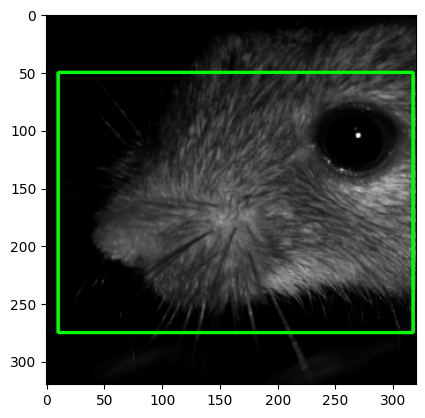

In [8]:
# Display the video with ROI
roi = [[10, 50, 307, 225]] #[[20, 45, 220, 190]] # [x, y, w, h]
ax, frame = None, None
for video in video_files:
    display_video_with_rois(video, roi)

### Select face + eye ROI

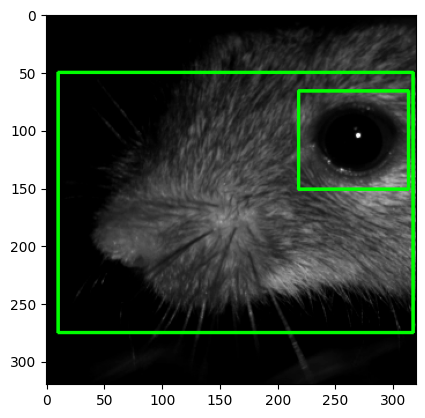

In [18]:
# Define two rectangles ROIs as (x, y, width, height)
full_face_roi = roi[0]
eye_roi = [218, 66, 95, 85]
rois = [full_face_roi, eye_roi]

ax, frame = None, None
for video in video_files:
    display_video_with_rois(video, rois)

### Crop video and save

In [19]:
roi_x, roi_y, roi_w, roi_h = full_face_roi
for video in video_files:
    output_path = video.replace('full', 'fullface')  # Output video path
    crop_and_save_video(video, output_path, roi_x, roi_y, roi_w, roi_h)

In [20]:
for video in video_files:
    output_path = video.replace('full', 'face-eye')  
    process_and_save_video(video, output_path, full_face_roi, eye_roi)

In [21]:
# Save ROI
np.save(os.path.join(video_path, '{m}_{s}_{b}_roi.npy'.format(m=mouse, s=session, b=blk[0])), {'full_face': full_face_roi, 'eye': eye_roi})

### Process and save SVD

In [22]:
fullface_video_list = []
face_eye_video_list = []
for video in video_files:
    v = video.replace('full', 'fullface')
    fullface_video_list.append([v])
    v = video.replace('full', 'face-eye')
    face_eye_video_list.append([v])

In [23]:
face_eye_video_list, fullface_video_list

([['/home/asyeda/nas113/Atika/FXa8/2026_01_16/1/FXa8_2026_01_16_1_face-eye.mp4']],
 [['/home/asyeda/nas113/Atika/FXa8/2026_01_16/1/FXa8_2026_01_16_1_fullface.mp4']])

In [24]:
savename = process.run(face_eye_video_list, motSVD=True, movSVD=True)
print("Output saved in", savename)

Computing subsampled mean...
Computed subsampled mean at 0.41s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  1.17sec
computed svd chunk 1 / 15, time  9.62sec
computed svd chunk 2 / 15, time  17.81sec
computed svd chunk 3 / 15, time  27.09sec
computed svd chunk 4 / 15, time  35.27sec
computed svd chunk 5 / 15, time  43.92sec
computed svd chunk 6 / 15, time  52.09sec
computed svd chunk 7 / 15, time  60.78sec
computed svd chunk 8 / 15, time  69.22sec
computed svd chunk 9 / 15, time  77.59sec
computed svd chunk 10 / 15, time  86.18sec
computed svd chunk 11 / 15, time  94.32sec
computed svd chunk 12 / 15, time  102.91sec
computed svd chunk 13 / 15, time  110.75sec
computed svd chunk 14 / 15, time  118.55sec
Computed subsampled SVD at 141.82s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 549, time  142.65sec
computed video chunk 10 / 549, time  149.86sec
computed video chunk 20 / 549, time  157.29sec
computed video chunk 30 / 549, time  164.61sec
computed video 

In [25]:
savename = process.run(fullface_video_list, motSVD=True, movSVD=True)
print("Output saved in", savename)

Computing subsampled mean...
Computed subsampled mean at 0.95s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  3.03sec
computed svd chunk 1 / 15, time  16.22sec
computed svd chunk 2 / 15, time  27.63sec
computed svd chunk 3 / 15, time  40.50sec
computed svd chunk 4 / 15, time  53.31sec
computed svd chunk 5 / 15, time  64.73sec
computed svd chunk 6 / 15, time  77.76sec
computed svd chunk 7 / 15, time  89.65sec
computed svd chunk 8 / 15, time  100.89sec
computed svd chunk 9 / 15, time  114.54sec
computed svd chunk 10 / 15, time  126.38sec
computed svd chunk 11 / 15, time  137.28sec
computed svd chunk 12 / 15, time  148.84sec
computed svd chunk 13 / 15, time  159.73sec
computed svd chunk 14 / 15, time  170.40sec
Computed subsampled SVD at 200.54s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 549, time  202.24sec
computed video chunk 10 / 549, time  218.33sec
computed video chunk 20 / 549, time  235.31sec
computed video chunk 30 / 549, time  251.60sec
computed v